In [ ]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt, seaborn as sns
from google.colab import files

uploaded = files.upload()   # a "Choose files" button appears: pick loans_clean.csv

Saving loans_clean.csv to loans_clean.csv


In [ ]:
df.shape

(32409, 2)

In [ ]:
df = pd.read_csv('loans_clean.csv', sep=';')
df['loan_id'] = range(1, len(df) + 1)

# The export wrote missing interest rates as 0 - turn them back into missing
df['loan_int_rate'] = df['loan_int_rate'].replace(0, np.nan)

print(df.shape)
print(df.isna().sum()[df.isna().sum() > 0])
df.head()

(32409, 15)
loan_int_rate    3094
dtype: int64


,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length,income_band,burden_band,loan_id
0,20,32652,MORTGAGE,0.0,PERSONAL,D,6000,14.61,1,0.18,N,4,2. 25K-50K,2. 10-20%,1
1,20,34800,RENT,3.0,MEDICAL,C,7000,13.61,0,0.20,Y,2,2. 25K-50K,3. 20-30%,2
2,20,42000,RENT,4.0,VENTURE,B,6500,11.71,0,0.15,N,2,2. 25K-50K,2. 10-20%,3
3,20,64000,RENT,3.0,VENTURE,D,16000,15.31,1,0.25,Y,4,3. 50K-75K,3. 20-30%,4
4,20,65000,MORTGAGE,4.0,EDUCATION,B,4800,9.99,0,0.07,N,2,3. 50K-75K,1. <10%,5


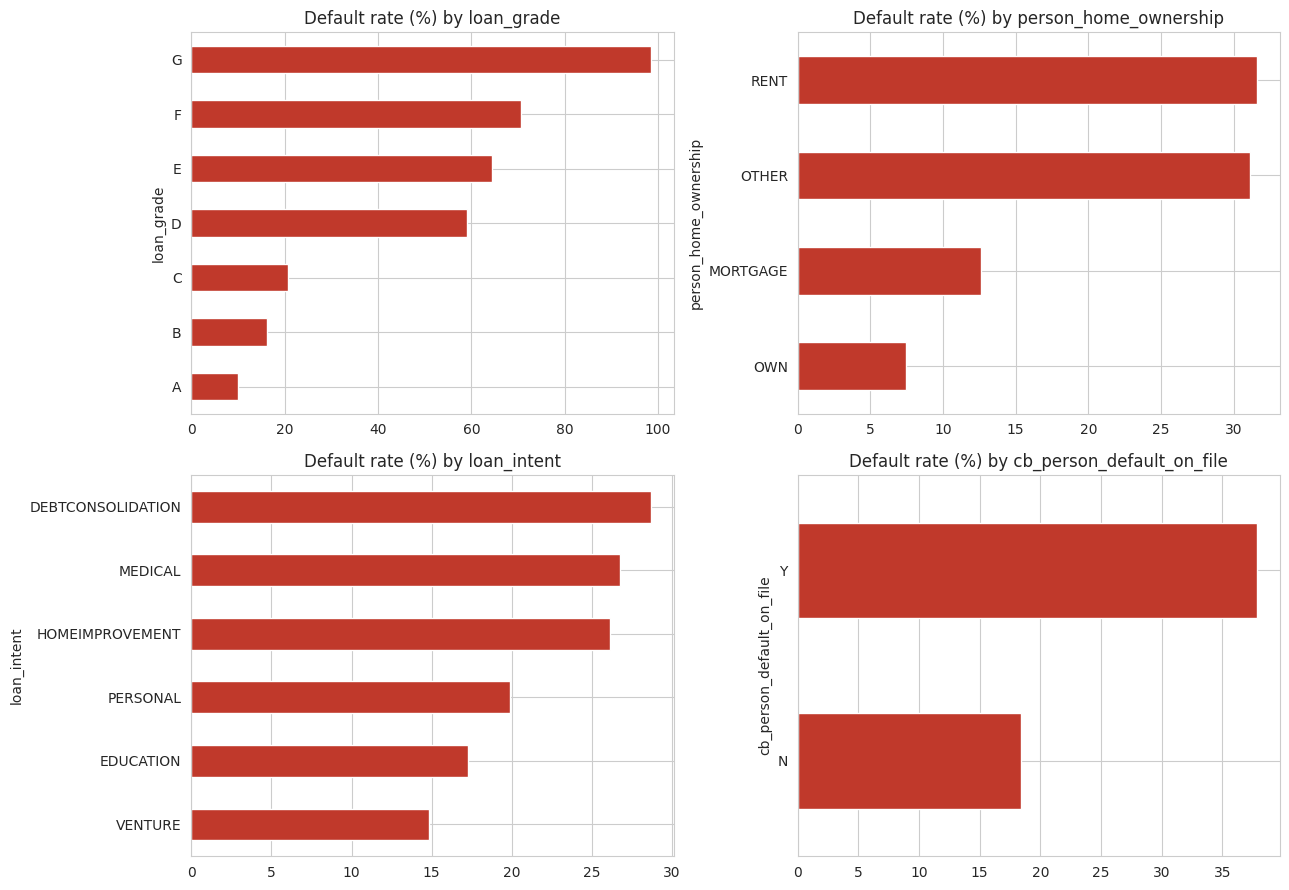

In [ ]:
sns.set_style('whitegrid')
fig, axes = plt.subplots(2, 2, figsize=(13, 9))
for ax, col in zip(axes.flat, ['loan_grade', 'person_home_ownership',
                               'loan_intent', 'cb_person_default_on_file']):
    rate = (df.groupby(col)['loan_status'].mean() * 100).sort_values()
    rate.plot(kind='barh', ax=ax, color='#c0392b')
    ax.set_title(f'Default rate (%) by {col}')
    ax.set_xlabel('')
plt.tight_layout()
plt.show()

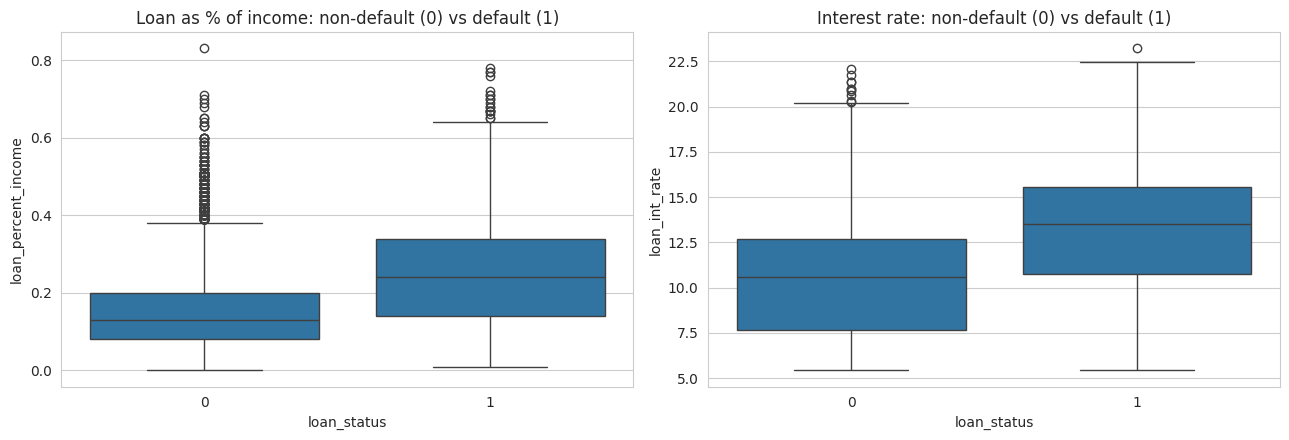

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
sns.boxplot(data=df, x='loan_status', y='loan_percent_income', ax=axes[0])
axes[0].set_title('Loan as % of income: non-default (0) vs default (1)')
sns.boxplot(data=df, x='loan_status', y='loan_int_rate', ax=axes[1])
axes[1].set_title('Interest rate: non-default (0) vs default (1)')
plt.tight_layout()
plt.show()

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# income_band and burden_band are just re-labelled versions of existing columns
X = df.drop(columns=['loan_status', 'loan_id', 'income_band', 'burden_band'])
y = df['loan_status']

num_cols = X.select_dtypes(include='number').columns.tolist()
cat_cols = X.select_dtypes(exclude='number').columns.tolist()

preprocess = ColumnTransformer([
    ('num', Pipeline([('impute', SimpleImputer(strategy='median')),
                      ('scale', StandardScaler())]), num_cols),
    ('cat', OneHotEncoder(handle_unknown='ignore'), cat_cols),
])

# stratify keeps the 22% default rate the same in both splits
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

===== Logistic Regression =====
Accuracy: 0.808
ROC-AUC : 0.865
              precision    recall  f1-score   support

 Non-default       0.93      0.82      0.87      5064
     Default       0.54      0.78      0.64      1418

    accuracy                           0.81      6482
   macro avg       0.74      0.80      0.75      6482
weighted avg       0.84      0.81      0.82      6482

Confusion matrix:
 [[4130  934]
 [ 313 1105]] 

===== Random Forest =====
Accuracy: 0.926
ROC-AUC : 0.93
              precision    recall  f1-score   support

 Non-default       0.93      0.97      0.95      5064
     Default       0.89      0.75      0.82      1418

    accuracy                           0.93      6482
   macro avg       0.91      0.86      0.88      6482
weighted avg       0.92      0.93      0.92      6482

Confusion matrix:
 [[4931  133]
 [ 349 1069]] 



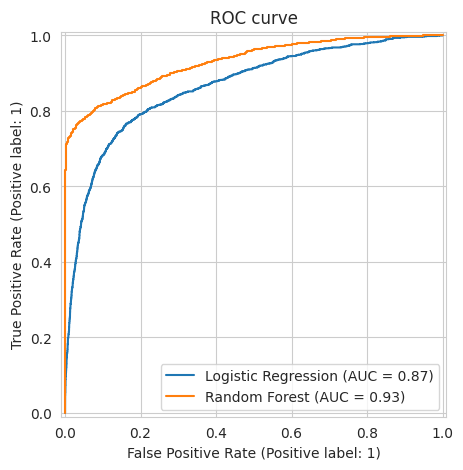

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, roc_auc_score, classification_report,
                             confusion_matrix, RocCurveDisplay)

models = {
    'Logistic Regression': LogisticRegression(max_iter=1000, class_weight='balanced'),
    'Random Forest': RandomForestClassifier(n_estimators=200, min_samples_leaf=5,
                                            class_weight='balanced',
                                            random_state=42, n_jobs=-1),
}

fitted = {}
fig, ax = plt.subplots(figsize=(6, 5))
for name, clf in models.items():
    pipe = Pipeline([('prep', preprocess), ('model', clf)])
    pipe.fit(X_train, y_train)
    fitted[name] = pipe
    pred = pipe.predict(X_test)
    proba = pipe.predict_proba(X_test)[:, 1]
    print(f'===== {name} =====')
    print('Accuracy:', round(accuracy_score(y_test, pred), 3))
    print('ROC-AUC :', round(roc_auc_score(y_test, proba), 3))
    print(classification_report(y_test, pred, target_names=['Non-default', 'Default']))
    print('Confusion matrix:\n', confusion_matrix(y_test, pred), '\n')
    RocCurveDisplay.from_predictions(y_test, proba, name=name, ax=ax)
ax.set_title('ROC curve')
plt.show()

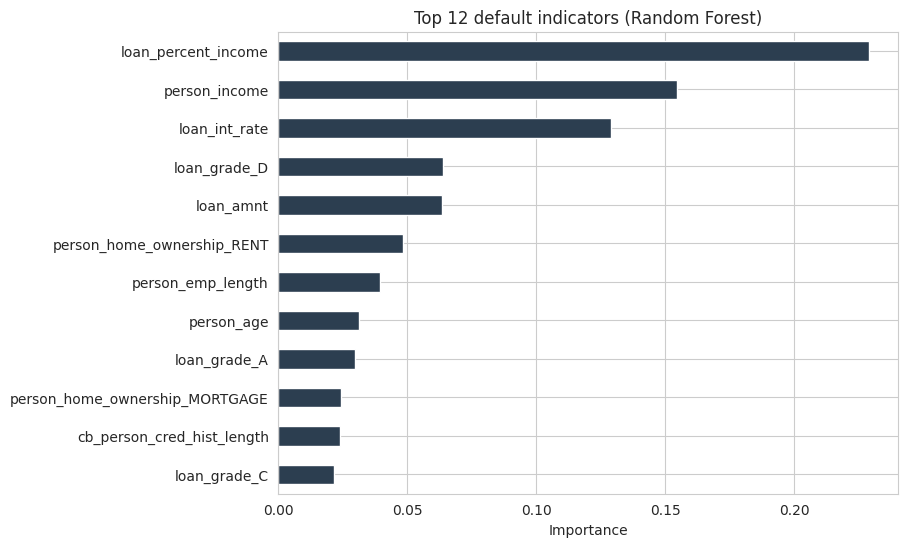

loan_percent_income               0.229
person_income                     0.155
loan_int_rate                     0.129
loan_grade_D                      0.064
loan_amnt                         0.063
person_home_ownership_RENT        0.048
person_emp_length                 0.039
person_age                        0.031
loan_grade_A                      0.030
person_home_ownership_MORTGAGE    0.024
cb_person_cred_hist_length        0.024
loan_grade_C                      0.021
dtype: float64


In [ ]:
rf = fitted['Random Forest']
names = rf.named_steps['prep'].get_feature_names_out()
names = [n.replace('num__', '').replace('cat__', '') for n in names]

imp = (pd.Series(rf.named_steps['model'].feature_importances_, index=names)
         .sort_values(ascending=False).head(12))

imp[::-1].plot(kind='barh', figsize=(8, 6), color='#2c3e50')
plt.title('Top 12 default indicators (Random Forest)')
plt.xlabel('Importance')
plt.show()
print(imp.round(3))

In [ ]:
from sklearn.model_selection import cross_val_predict

# Out-of-sample predictions for every row, so scores aren't inflated
rf_pipe = Pipeline([('prep', preprocess), ('model', models['Random Forest'])])
df['default_probability'] = cross_val_predict(
    rf_pipe, X, y, cv=5, method='predict_proba')[:, 1]

# Credit score: 900 = very safe, 300 = very risky
df['credit_score'] = (900 - 600 * df['default_probability']).round().astype(int)

df['risk_segment'] = pd.cut(df['default_probability'],
                            bins=[-0.01, 0.20, 0.50, 1.0],
                            labels=['Low Risk', 'Medium Risk', 'High Risk'])

# Simulated branch (the dataset has none) - mention this in your report
df['branch'] = df['loan_id'].mod(5).map(
    dict(enumerate(['Branch A', 'Branch B', 'Branch C', 'Branch D', 'Branch E'])))

print(df.groupby('risk_segment', observed=True)['loan_status']
        .agg(customers='count', actual_default_rate='mean').round(3))

df.to_csv('loans_scored.csv', index=False)
files.download('loans_scored.csv')

              customers  actual_default_rate
risk_segment                                
Low Risk          16729                0.047
Medium Risk        7795                0.117
High Risk          7885                0.684


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>